# A sediment clock with uncertain deposition

Fourteen **measured** excess-lead-210 concentrations from core LAZ07/02, collected in Lake Łazduny in2007, are inverted for bottom age, accumulation and initial activity. Independent varve ages are validation measurements, never fitted inputs. The original author provided the real profile and a full four-parameter χ map; its first two private reproductions took490.6 and439.3s. This notebook actively recomputes all810000 cases with local mathematics.

For layer thickness Δm and positive accumulation w, duration Δt=Δm/w. Its bottom age is cumulative duration, and its average activity is

$$
\bar A=A_0\exp(-\lambda t_{\mathrm{previous}})
\frac{1-\exp(-\lambda\Delta t)}{\lambda\Delta t},\quad\lambda=0.03118\ \mathrm{yr}^{-1}.
$$

A₀ is initial activity inBq/kg; w is ing/cm²/yr; ages are years before collection. The integral averages radioactive decay over the whole layer. Simultaneous A₀ and w variability makes chronology nonunique. Pair canonical normally distributed samples, greedily arrange the remaining pairs top-down, scan their means/relative deviations and score χν=√[Σ((Ā−A)/σ)²/(14−4)]. The exact native grid, original decimal exchange conventions and all three confidence groups are preserved. Batching independent cases accelerates the computation without changing this method.

In [1]:
from pathlib import Path
import os,sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
TASK=Path.cwd()
if not (TASK/'src').exists(): TASK=TASK.parent
sys.path.insert(0,str(TASK));os.chdir(TASK)
from src.preprocessing import load_observations
from src.solvers import reconstruct
from src.visualization import confidence_envelopes
observations=load_observations();mass,measured,error=observations
start=time.perf_counter();fresh,details=reconstruct(*observations);primary_seconds=time.perf_counter()-start
result={'reconstruction':fresh[None,2],'sedimentation_rate':fresh[None,1],'initial_activity':fresh[None,0],'modeled_activity':fresh[None,3]}
np.savez('output/reconstruction.npz',**result)
spec=importlib.util.spec_from_file_location('independent_judge',TASK/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(TASK/'output/reconstruction.npz');assert report['passed'],report
with np.load('evaluation/ground_truth.npz') as truth:
    varve=truth['reconstruction'][0];varve_error=truth['age_uncertainty'][0]
with np.load('notebooks/reference_outputs/upstream_profiles.npz') as archived:
    upstream=archived['profile'];upstream_alternative=archived['profile_20261030']
print('Fresh native full-grid seconds:',primary_seconds)
print('Fresh grid cases:',len(details['grid']),'all confidence groups:',[len(c) for c in details['cloud_parameters']])
print('Fresh independently evaluated metrics:',json.dumps(report['metrics'],indent=2))
print('Maximum original/fresh age difference (yr):',np.max(abs(fresh[2]-upstream[2])))

Fresh native full-grid seconds: 3.4634459000080824
Fresh grid cases: 810000 all confidence groups: [481, 7864, 25064]
Fresh independently evaluated metrics: {
  "age_ncc": 0.9988448437488565,
  "age_nrmse": 0.03724698397612326,
  "observation_chi": 0.5846476186104412,
  "age_rate_relative_consistency": 4.500904153885774e-16,
  "decay_relative_consistency": 4.521039090724916e-16
}
Maximum original/fresh age difference (yr): 0.0


## Full activity data, real independent ages and every confidence group

The three groups partition the four-parameter68.3% χ² region, using Δχ²=4.72. Each envelope below uses **every** selected solver, not a display subsample. Groups1,2,3 contain481,7864,25064 cases respectively. Envelopes show model spread and do not claim guaranteed frequentist coverage of the true chronology. Activity error bars are analytical standard deviations; varve error bars are independent reported age uncertainties. Age is evaluated at layer **bottoms**, activity at mass-depth **midpoints**.

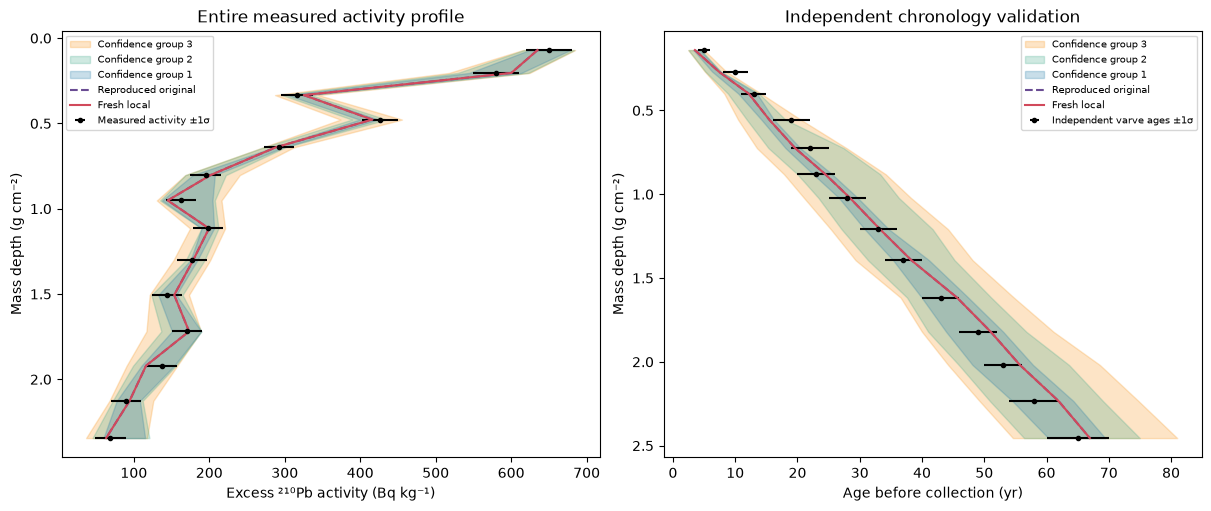

In [2]:
envelopes=confidence_envelopes(details,observations)
mid=(mass+np.r_[0.,mass[:-1]])/2
colors=['#277da8','#43aa8b','#f8961e']
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
for index in [2,1,0]:
    lower,median,upper=envelopes[index]
    axes[0].fill_betweenx(mid,lower[3],upper[3],color=colors[index],alpha=.25,label=f'Confidence group {index+1}')
    axes[1].fill_betweenx(mass,lower[2],upper[2],color=colors[index],alpha=.25,label=f'Confidence group {index+1}')
axes[0].errorbar(measured,mid,xerr=error,fmt='k.',label='Measured activity ±1σ')
axes[0].plot(upstream[3],mid,'--',color='#6a4c93',label='Reproduced original')
axes[0].plot(fresh[3],mid,'-',color='#d1495b',label='Fresh local')
axes[1].errorbar(varve,mass,xerr=varve_error,fmt='k.',label='Independent varve ages ±1σ')
axes[1].plot(upstream[2],mass,'--',color='#6a4c93',label='Reproduced original')
axes[1].plot(fresh[2],mass,'-',color='#d1495b',label='Fresh local')
for ax in axes:ax.invert_yaxis();ax.set_ylabel('Mass depth (g cm⁻²)');ax.legend(fontsize=7)
axes[0].set_xlabel('Excess ²¹⁰Pb activity (Bq kg⁻¹)');axes[0].set_title('Entire measured activity profile')
axes[1].set_xlabel('Age before collection (yr)');axes[1].set_title('Independent chronology validation')
fig.savefig('output/teresa_chronology.png',dpi=160);plt.show()

## Actual experiment: sensitivity to an independent normal pairing

The model samples plausible distributions rather than uniquely identifying a layer-by-layer history. We now actively rerun the same complete810000-case inverse with a second independent proposal library. The original implementation was separately run on that library before local extraction. Compare both fresh outputs with their correctly identified original runs and with independent varves. This experiment changes algorithm randomness, not measured data, search resolution or pass thresholds.

Fresh independent full-grid seconds: 4.880255199968815
[
  {
    "method": "Original primary",
    "age_RMSE_yr": 2.234819038567396,
    "age_NRMSE": 0.03724698397612326,
    "activity_chi": 0.5846476186104412
  },
  {
    "method": "Fresh primary",
    "age_RMSE_yr": 2.234819038567396,
    "age_NRMSE": 0.03724698397612326,
    "activity_chi": 0.5846476186104412
  },
  {
    "method": "Original independent pairing",
    "age_RMSE_yr": 3.520709466268546,
    "age_NRMSE": 0.05867849110447577,
    "activity_chi": 0.5201539778672771
  },
  {
    "method": "Fresh independent pairing",
    "age_RMSE_yr": 3.520709466268546,
    "age_NRMSE": 0.05867849110447577,
    "activity_chi": 0.520153977867277
  }
]
Independent original/fresh maximum profile difference: 2.842170943040401e-14


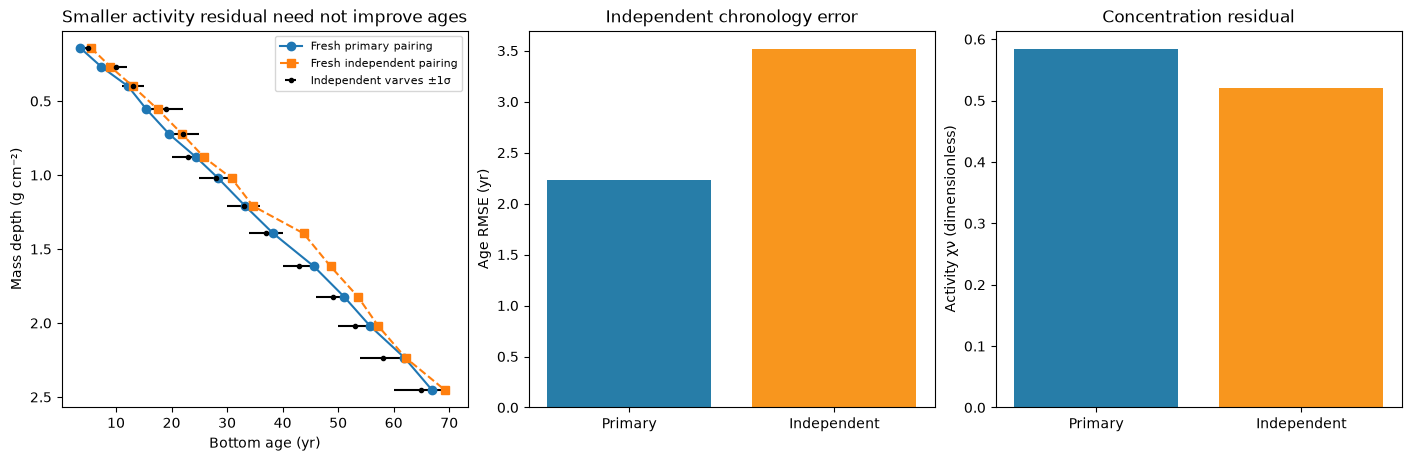

In [3]:
start=time.perf_counter();alternate,alternate_details=reconstruct(*observations,seed=20261030);alternative_seconds=time.perf_counter()-start
table=[]
for label,p in [('Original primary',upstream),('Fresh primary',fresh),('Original independent pairing',upstream_alternative),('Fresh independent pairing',alternate)]:
    age_error=np.sqrt(np.mean((p[2]-varve)**2))
    obs_chi=np.sqrt(np.sum(((p[3]-measured)/error)**2)/10)
    table.append({'method':label,'age_RMSE_yr':float(age_error),'age_NRMSE':float(age_error/np.ptp(varve)),'activity_chi':float(obs_chi)})
print('Fresh independent full-grid seconds:',alternative_seconds)
print(json.dumps(table,indent=2))
print('Independent original/fresh maximum profile difference:',np.max(abs(alternate-upstream_alternative)))
fig,axes=plt.subplots(1,3,figsize=(14,4.5),layout='constrained')
axes[0].errorbar(varve,mass,xerr=varve_error,fmt='k.',label='Independent varves ±1σ')
axes[0].plot(fresh[2],mass,'o-',label='Fresh primary pairing')
axes[0].plot(alternate[2],mass,'s--',label='Fresh independent pairing')
axes[0].invert_yaxis();axes[0].set(xlabel='Bottom age (yr)',ylabel='Mass depth (g cm⁻²)',title='Smaller activity residual need not improve ages');axes[0].legend(fontsize=8)
x=np.arange(2)
axes[1].bar(x,[table[1]['age_RMSE_yr'],table[3]['age_RMSE_yr']],color=['#277da8','#f8961e'])
axes[2].bar(x,[table[1]['activity_chi'],table[3]['activity_chi']],color=['#277da8','#f8961e'])
for ax in axes[1:]:ax.set_xticks(x,['Primary','Independent'])
axes[1].set(ylabel='Age RMSE (yr)',title='Independent chronology error')
axes[2].set(ylabel='Activity χν (dimensionless)',title='Concentration residual')
fig.savefig('output/teresa_sensitivity.png',dpi=160);plt.show()

## What deposition histories explain the measurements?

These initial activities and accumulation rates are **model estimates**, not independent ground truth. All three confidence groups are retained. Multiplying A₀ by w and10 gives deposition flux inBq/m²/yr. The χ-map panel marginalizes over the two dispersion axes using the minimum score, displaying every mean-activity/mean-rate grid location. The selected optimum is internal in those two coordinates, while its relative-rate dispersion lies at the lower grid boundary. That boundary and the pairing experiment limit claims of a unique history.

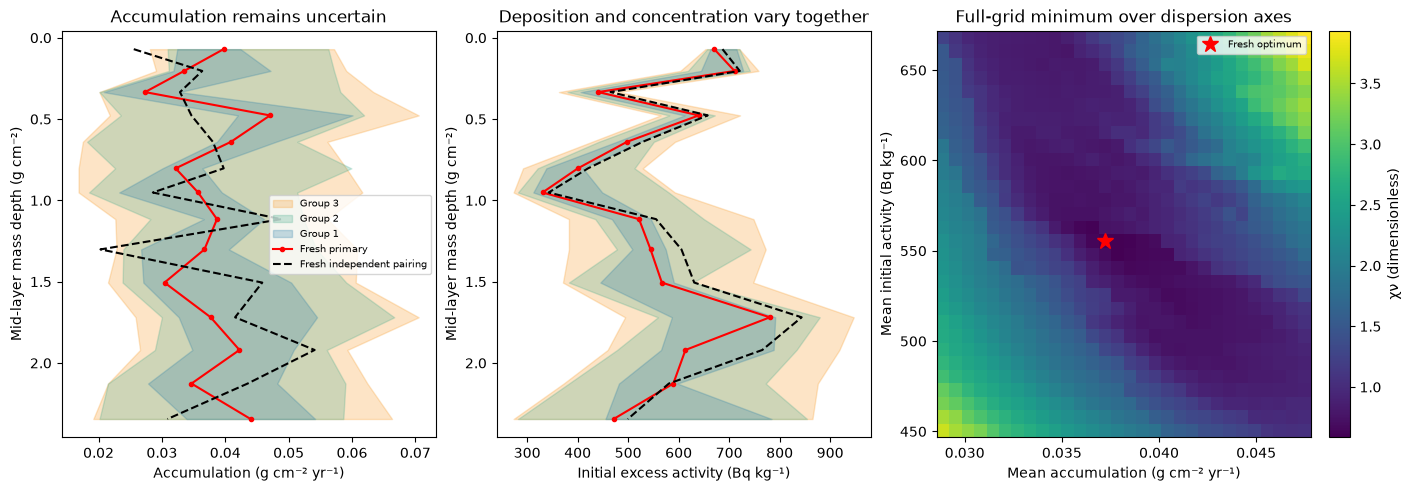

Primary fresh Judge passed: True
The primary result agrees with independent ages at RMSE 2.234819038567396 yr; neither pairing is asserted to be the unique actual deposition history.


In [4]:
fig,axes=plt.subplots(1,3,figsize=(14,4.8),layout='constrained')
for index in [2,1,0]:
    lower,median,upper=envelopes[index]
    axes[0].fill_betweenx(mid,lower[1],upper[1],color=colors[index],alpha=.25,label=f'Group {index+1}')
    axes[1].fill_betweenx(mid,lower[0],upper[0],color=colors[index],alpha=.25)
axes[0].plot(fresh[1],mid,'r.-',label='Fresh primary');axes[0].plot(alternate[1],mid,'k--',label='Fresh independent pairing')
axes[1].plot(fresh[0],mid,'r.-');axes[1].plot(alternate[0],mid,'k--')
for ax in axes[:2]:ax.invert_yaxis();ax.set_ylabel('Mid-layer mass depth (g cm⁻²)')
axes[0].set_xlabel('Accumulation (g cm⁻² yr⁻¹)');axes[0].set_title('Accumulation remains uncertain');axes[0].legend(fontsize=7)
axes[1].set_xlabel('Initial excess activity (Bq kg⁻¹)');axes[1].set_title('Deposition and concentration vary together')
landscape=details['scores'].reshape(30,30,30,30).min(axis=(2,3))
axis_a=np.unique(details['grid'][:,0]);axis_w=np.unique(details['grid'][:,1])
image=axes[2].pcolormesh(axis_w,axis_a,landscape,cmap='viridis',shading='nearest')
axes[2].plot(details['parameters'][1],details['parameters'][0],'r*',ms=12,label='Fresh optimum')
axes[2].set(xlabel='Mean accumulation (g cm⁻² yr⁻¹)',ylabel='Mean initial activity (Bq kg⁻¹)',title='Full-grid minimum over dispersion axes');axes[2].legend(fontsize=7)
from matplotlib.ticker import MaxNLocator
axes[2].xaxis.set_major_locator(MaxNLocator(4))
fig.colorbar(image,ax=axes[2],label='χν (dimensionless)')
fig.savefig('output/teresa_deposition.png',dpi=160);plt.show()
print('Primary fresh Judge passed:',report['passed'])
print('The primary result agrees with independent ages at RMSE',table[1]['age_RMSE_yr'],'yr; neither pairing is asserted to be the unique actual deposition history.')